# Short-List Promising Models & Fine-Tune the System

**Where each checklist item is in this notebook**

| Checklist item | Section |
|---|---|
| **Short-list 1.** Train many quick models from different categories | *Part 2: Comparing different models* (7 models: dummy, logistic regression, KNN, SVM, naive Bayes, random forest, gradient boosting) |
| **Short-list 2.** N-fold cross-validation, mean and standard deviation | Repeated 5-fold CV (50 fits per model) with mean, sd and boxplots |
| **Short-list 3.** Most significant variables for each algorithm | *Most significant variables for each model* (permutation importance + logistic regression coefficients) |
| **Short-list 4.** Types of errors the models make | *Types of errors* (missed early springs vs. wasted seeds, which years, what a human would have needed) |
| **Short-list 5–6.** Quick round(s) of feature selection / engineering | Done in the Preparation notebook; here the preparation choices are tuned as hyperparameters |
| **Short-list 7.** Short-list 3–5 models, preferring different types of errors | *Which models to continue with* |
| **Fine-tune 1.** Tune hyperparameters with CV, data transformations as hyperparameters, random search | *Fine-tuning* (randomized search, 9 preprocessing + 2–11 model hyperparameters per model) |
| **Fine-tune 2.** Try ensemble methods | Tuned random forest and gradient boosting (20 hyperparameters each) + a soft-voting ensemble |
| **Fine-tune 3.** Measure the final model on the test set once | *Final evaluation on the test set* (selection rule fixed before loading the test set; nothing changed afterwards) |

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns
import pickle


from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold
from sklearn.model_selection import cross_val_score, cross_val_predict, cross_validate
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_curve, roc_curve, roc_auc_score

# Our preparation code (must be importable, so pickles can find the classes)
import early_spring_prep as prep
from early_spring_prep import TARGET, SEED_COST, make_preprocessor, profit_per_year, profit_score

RANDOM_STATE = 42
from sklearn.base import clone

We start from what the Preparation notebook produced:

* `train_set.parquet` / `test_set.parquet`, with `early_spring` as the label.
* `early_spring_prep.py`, with `make_preprocessor()` (the `small` feature set by default: `year`, `air_feb`, `snow_days`, `soil_moisture`), and the business measure `profit_per_year` / `profit_score`.
* The same cross-validation as in Preparation (5 folds, repeated), because ~57 years with 11 early springs make a single split very noisy.

**The preprocessor goes inside every model's `Pipeline`**, so imputing and scaling are re-fit on the training part of each fold and nothing leaks from the validation fold. We do not use the fitted `preprocessor.pkl` here, because it has already seen all the training years.

**The test set is not used in this notebook** until the final evaluation.

In [2]:
# Get the training data (the test set is NOT loaded here)
train_set = pd.read_parquet("train_set.parquet")
train_set.head()

,year,phil_early,snow_days,cold_days,gdd,air_feb_late,soil_feb_late,soil_moisture,air_feb,soil_feb,...,soil_moisture_late,oni_son,oni_ond,oni_ndj,oni_trend,ao_nov,ao_dec,ao_jan,ao_winter_mean,early_spring
0,1947,False,21.0,21.0,58.0,24.166667,-0.017778,0.464049,21.642857,-1.873661,...,0.464364,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1948,False,17.0,15.0,31.5,36.966667,1.385278,0.471476,28.586207,0.754023,...,0.492517,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1949,False,7.0,11.0,115.5,41.266667,3.257222,0.485908,36.750000,2.362649,...,0.488389,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True
3,1950,True,8.0,10.0,136.5,28.400000,-0.298611,0.476948,30.803571,0.302827,...,0.477081,NaN,NaN,NaN,NaN,NaN,NaN,-0.0603,NaN,False
4,1951,False,9.0,8.0,62.5,38.966667,1.978333,0.483156,32.214286,0.772024,...,0.481406,-0.62,-0.66,-0.79,-0.17,-0.5151,-1.9281,-0.0850,-0.842733,True


In [3]:
# Split the features (X) from the labels (y)
X_train = train_set.drop(columns=TARGET)
y_train = train_set[TARGET].astype(bool)

print(f"{X_train.shape[0]} years, {X_train.shape[1]} columns, {y_train.sum()} early springs ({y_train.mean():.0%})")

57 years, 21 columns, 11 early springs (19%)


Binary classification with one model (Logistic Regression)
==================================================================

In [4]:
# Look at the first 15 labels
y_train[:15].array

<NumpyExtensionArray>
[False, False,  True, False,  True, False,  True, False, False, False, False,
 False, False, False, False]
Length: 15, dtype: bool

In [5]:
# The business measure: buying seeds gains 0.8 if spring is early and loses 0.2 if it is not.
# These are the naive strategies any model has to beat
phil = X_train["phil_early"].fillna(False).astype(bool)
print("Never buy:  ", profit_per_year(y_train, np.zeros(len(y_train))))
print("Always buy: ", round(profit_per_year(y_train, np.ones(len(y_train))), 4))
print("Follow Phil:", round(profit_per_year(y_train, phil), 4))

Never buy:   0.0
Always buy:  -0.007
Follow Phil: -0.014


In [6]:
# Make a Logistic Regression classifier behind the preprocessor, fit it to the data (train),
# and predict the first 15 results
def with_prep(model, **prep_params):
    # Preprocessing is re-fit inside every cross-validation fold
    return Pipeline([("prep", make_preprocessor(**prep_params)), ("model", model)])

log_reg = with_prep(LogisticRegression(C=0.1, max_iter=5000))
log_reg.fit(X_train, y_train)
y_pred = log_reg.predict(X_train)
y_pred[:15], y_train[:15].array

(array([False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False]),
 <NumpyExtensionArray>
 [False, False,  True, False,  True, False,  True, False, False, False, False,
  False, False, False, False]
 Length: 15, dtype: bool)

In [7]:
# Accuracy on the data it was trained on (looks better than it really is)
(y_pred == y_train).mean()

np.float64(0.8245614035087719)

In [8]:
# Use cross validation with 5 folds and using accuracy scoring
# NOTE: ~57 years only, so look at the spread of the scores, not just the mean
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(log_reg, X_train, y_train, cv=cv, scoring="accuracy")
scores, scores.mean()

(array([0.83333333, 0.75      , 0.81818182, 0.81818182, 0.81818182]),
 np.float64(0.8075757575757576))

In [9]:
# Accuracy of the "never buy" strategy (always predict "not early") for comparison
1 - y_train.mean()

np.float64(0.8070175438596492)

In [10]:
# Use cross validation to get the prediction and then use those to calculate the confusion matrix
y_train_pred = cross_val_predict(log_reg, X_train, y_train, cv=cv)
cm = confusion_matrix(y_train, y_train_pred)
cm

array([[46,  0],
       [11,  0]])

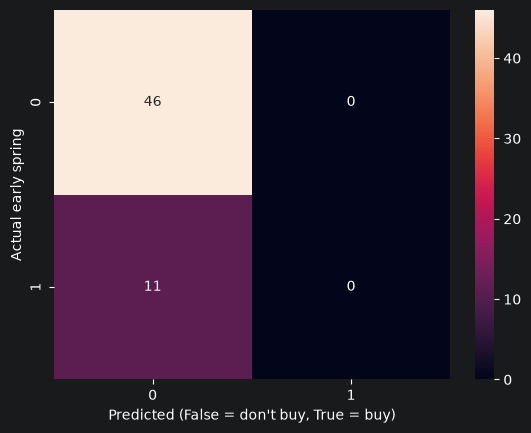

In [11]:
# View the confusion matrix with Seaborn
sns.heatmap(cm, annot=True, fmt="d")
plt.xlabel("Predicted (False = don't buy, True = buy)")
plt.ylabel("Actual early spring")
plt.show()

In [12]:
# Break up the confusion matrix into its 4 values
(TN,FP),(FN,TP) = cm

# Compute accuracy, precision, and recall
accuracy  = (TP+TN)/(TP+TN+FP+FN)
precision = TP/(TP+FP) if TP+FP else 0    # of the years we bought, how many were really early
recall    = TP/(TP+FN)                    # of the early springs, how many we caught
f1 = 2 * (precision * recall) / (precision + recall) if precision + recall else 0

accuracy, precision, recall, f1

(np.float64(0.8070175438596491), 0, np.float64(0.0), 0)

In [13]:
# Calculate basic metrics
accuracy  = accuracy_score (y_train, y_train_pred) # (TP+TN)/(TN+TP+FN+FP)
precision = precision_score(y_train, y_train_pred, zero_division=0) # TP/(TP+FP)
recall    = recall_score   (y_train, y_train_pred) # TP/(TP+FN)
f1 = f1_score(y_train, y_train_pred) # 2*precision*recall/(precision+recall)
accuracy, precision, recall, f1

(0.8070175438596491, 0.0, 0.0, 0.0)

In [14]:
# Profit per year if we follow these predictions
profit_per_year(y_train, y_train_pred)

0.0

In [15]:
# Get the probability of an early spring for every year (out-of-fold: the model never saw that year)
y_scores = cross_val_predict(log_reg, X_train, y_train, cv=cv, method="predict_proba")[:,1]
y_scores[:10].round(2)

array([0.06, 0.12, 0.35, 0.21, 0.27, 0.31, 0.3 , 0.32, 0.16, 0.32])

In [16]:
# Show the effect of changing the threshold on the precision/recall/profit tradeoff
# NOTE: break-even is 0.2 (we only need to be right 1 time in 5 to not lose money)
print("Threshold Precision Recall    F1 Score  Profit/yr")
for thresh in [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]:
    buy = y_scores > thresh
    prec = precision_score(y_train, buy, zero_division=0)
    recall = recall_score(y_train, buy)
    f1 = f1_score(y_train, buy, zero_division=0)
    print(f"{thresh:9.2f} {prec:.7f} {recall:.7f} {f1:.7f} {profit_per_year(y_train, buy):9.3f}")

Threshold Precision Recall    F1 Score  Profit/yr
     0.10 0.2500000 1.0000000 0.4000000     0.039
     0.15 0.2727273 0.8181818 0.4090909     0.042
     0.20 0.3076923 0.7272727 0.4324324     0.049
     0.25 0.4705882 0.7272727 0.5714286     0.081
     0.30 0.4285714 0.5454545 0.4800000     0.056
     0.40 1.0000000 0.0909091 0.1666667     0.014
     0.50 0.0000000 0.0000000 0.0000000     0.000


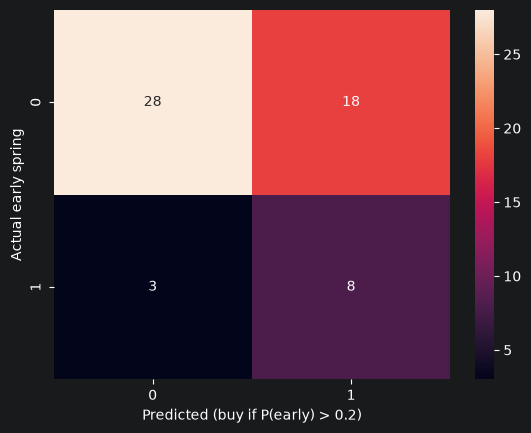

In [17]:
# Confusion matrix at the break-even threshold of 0.2 (instead of the default 0.5)
cm_02 = confusion_matrix(y_train, y_scores > SEED_COST)
sns.heatmap(cm_02, annot=True, fmt="d")
plt.xlabel("Predicted (buy if P(early) > 0.2)")
plt.ylabel("Actual early spring")
plt.show()

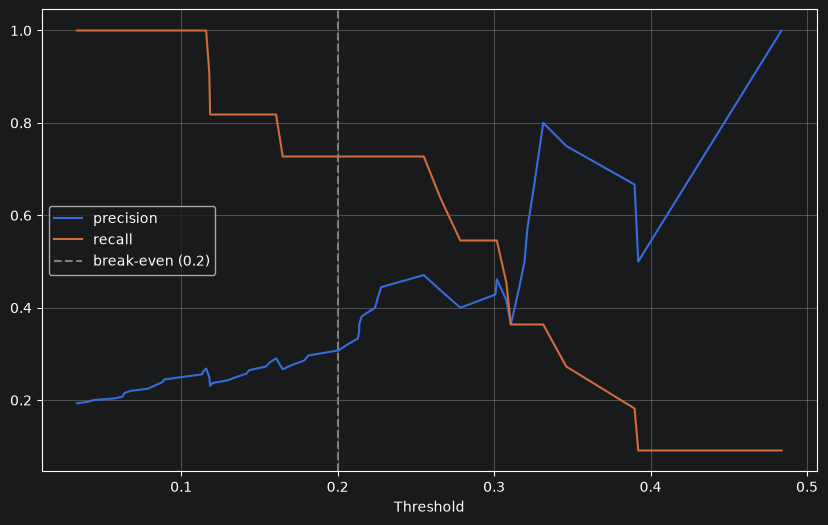

In [18]:
# Get the precision and recall curves
plt.figure(figsize=(10, 6))
precs, recalls, threshs = precision_recall_curve(y_train, y_scores)
plt.plot(threshs, precs[:-1], label="precision")
plt.plot(threshs, recalls[:-1], label="recall")
plt.axvline(SEED_COST, color="gray", linestyle="--", label="break-even (0.2)")
plt.grid()
plt.xlabel("Threshold")
plt.legend()
plt.show()

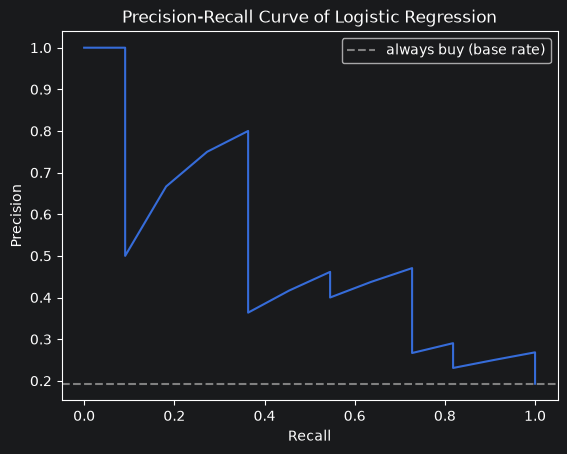

In [19]:
# Plot them against each other - the precision-recall curve
plt.plot(recalls, precs)
plt.axhline(y_train.mean(), color="gray", linestyle="--", label="always buy (base rate)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve of Logistic Regression")
plt.legend()
plt.show()

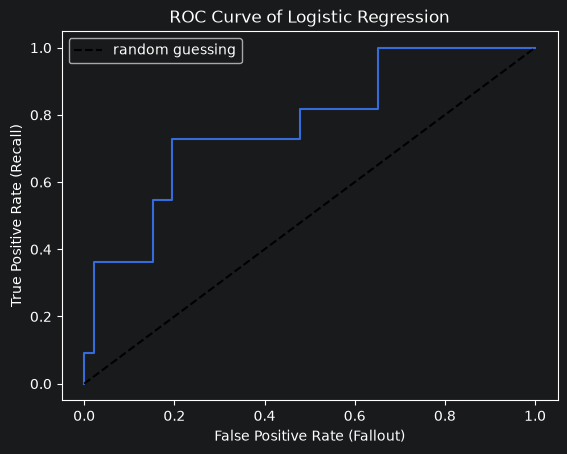

In [20]:
# Plot ROC curve
fpr, tpr, threshs = roc_curve(y_train, y_scores)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], "k--", label="random guessing")
plt.xlabel("False Positive Rate (Fallout)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve of Logistic Regression")
plt.legend()
plt.show()

In [21]:
# Calculate the ROC Area Under the Curve
auc = roc_auc_score(y_train, y_scores)
auc

0.7687747035573123

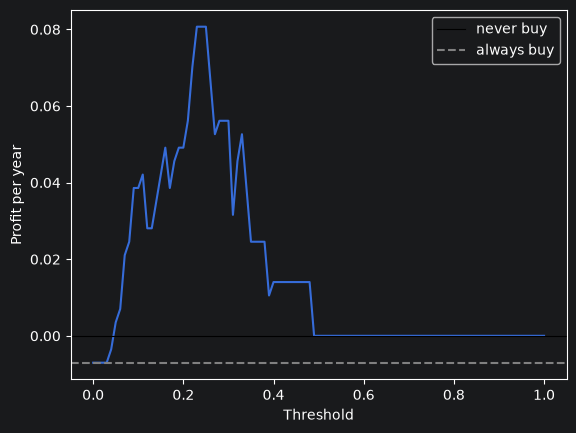

(np.float64(0.23), 0.08070175438596493)

In [22]:
# Profit per year at every threshold - the best one is the buy / don't-buy cutoff
thresholds = np.linspace(0, 1, 101)
profits = [profit_per_year(y_train, y_scores > t) for t in thresholds]

plt.plot(thresholds, profits)
plt.axhline(0, color="black", linewidth=0.8, label="never buy")
plt.axhline(profit_per_year(y_train, np.ones(len(y_train))), color="gray", linestyle="--", label="always buy")
plt.xlabel("Threshold")
plt.ylabel("Profit per year")
plt.legend()
plt.show()

# NOTE: picked on the same years it is scored on, so this best value is optimistic
thresholds[np.argmax(profits)], max(profits)

Part 2: Comparing different models
==================================
At least 6 model families, all behind the same preprocessor and scored with the same cross-validation, so the numbers are comparable. Models that don't need scaling (trees) get `scaler="none"`.

In [23]:
# The models to try
pipelines = {
    "Dummy (base rate)":   with_prep(DummyClassifier(strategy="prior")),
    "Logistic Regression": with_prep(LogisticRegression(C=0.1, max_iter=5000)),
    "KNN":                 with_prep(KNeighborsClassifier(n_neighbors=7)),
    # SVC(probability=True) is deprecated in new scikit-learn, so calibrate it instead
    "SVM (RBF)":           with_prep(CalibratedClassifierCV(SVC(), method="sigmoid", cv=3, ensemble=False)),
    "Naive Bayes":         with_prep(GaussianNB()),
    "Random Forest":       with_prep(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE), scaler="none"),
    "Gradient Boosting":   with_prep(GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=RANDOM_STATE), scaler="none"),
}

In [24]:
# Compute the out-of-fold probabilities for every model
all_scores = {}
for name, pipe in pipelines.items():
    all_scores[name] = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:,1]

In [25]:
# Compute the scores for all models using the break-even threshold of 0.2 (buy if there is more than a 20% chance)
rows = []
for name, scores in all_scores.items():
    buy = scores > SEED_COST
    rows.append({"model": name,
                 "accuracy":  accuracy_score(y_train, buy),
                 "precision": precision_score(y_train, buy, zero_division=0),
                 "recall":    recall_score(y_train, buy),
                 "f1":        f1_score(y_train, buy, zero_division=0),
                 "roc_auc":   roc_auc_score(y_train, scores),
                 "profit/yr": profit_per_year(y_train, buy)})
results = pd.DataFrame(rows).set_index("model").round(3)
results.sort_values("profit/yr", ascending=False)

,accuracy,precision,recall,f1,roc_auc,profit/yr
model,,,,,,
KNN,0.737,0.400,0.727,0.516,0.699,0.070
Naive Bayes,0.719,0.381,0.727,0.500,0.765,0.067
Random Forest,0.737,0.389,0.636,0.483,0.704,0.060
SVM (RBF),0.754,0.400,0.545,0.462,0.634,0.053
Logistic Regression,0.632,0.308,0.727,0.432,0.769,0.049
Gradient Boosting,0.702,0.250,0.273,0.261,0.611,0.011
Dummy (base rate),0.807,0.000,0.000,0.000,0.456,0.000


In [26]:
# Reference lines: what the naive strategies earn on the same years
print("Never buy:  ", profit_per_year(y_train, np.zeros(len(y_train))))
print("Always buy: ", round(profit_per_year(y_train, np.ones(len(y_train))), 4))
print("Follow Phil:", round(profit_per_year(y_train, phil), 4))

Never buy:   0.0
Always buy:  -0.007
Follow Phil: -0.014


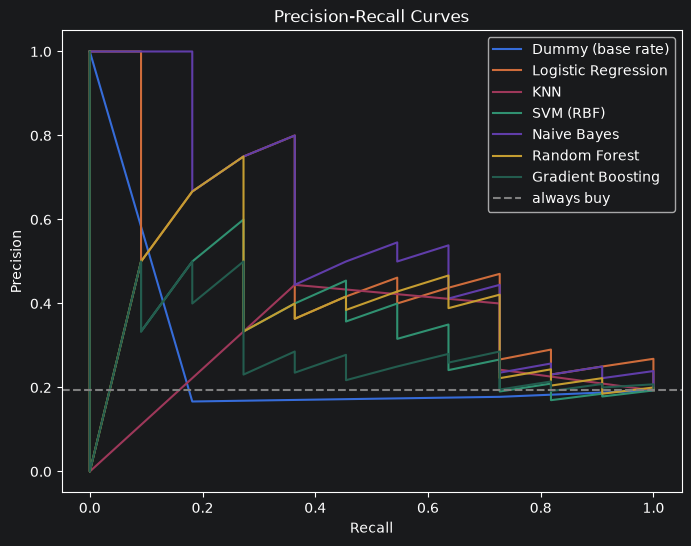

In [27]:
# Plot all models - Precision vs Recall
plt.figure(figsize=(8, 6))
for name, scores in all_scores.items():
    p, r, _ = precision_recall_curve(y_train, scores)
    plt.plot(r, p, label=name)
plt.axhline(y_train.mean(), color="gray", linestyle="--", label="always buy")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.show()

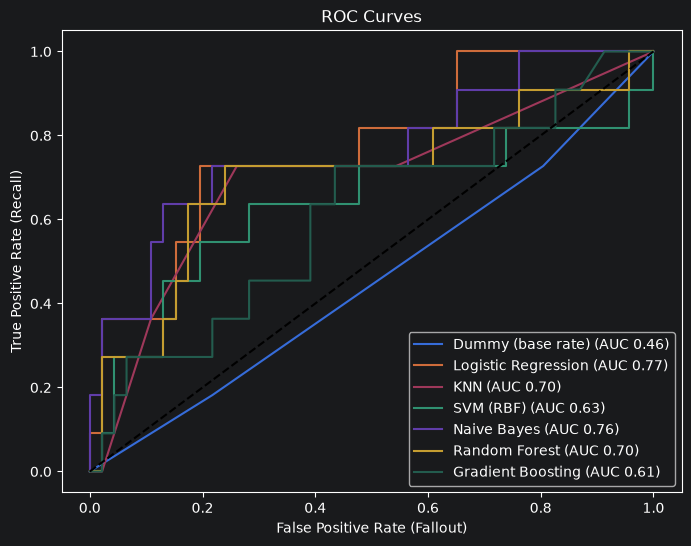

In [28]:
# Plot all models - ROC
plt.figure(figsize=(8, 6))
for name, scores in all_scores.items():
    f, t, _ = roc_curve(y_train, scores)
    plt.plot(f, t, label=f"{name} (AUC {roc_auc_score(y_train, scores):.2f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate (Fallout)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves")
plt.legend()
plt.show()

In [29]:
# One 5-fold split is noisy with so few early springs, so repeat the cross validation 10 times
# (50 fits per model, same setup as in Preparation) and look at the spread
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
auc_runs, profit_runs = {}, {}
for name, pipe in pipelines.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv_rep, n_jobs=-1,
                       scoring={"auc": "roc_auc", "profit": profit_score})
    auc_runs[name], profit_runs[name] = r["test_auc"], r["test_profit"]
auc_runs, profit_runs = pd.DataFrame(auc_runs), pd.DataFrame(profit_runs)

summary = pd.DataFrame({"AUC mean": auc_runs.mean(), "AUC sd": auc_runs.std(),
                        "profit mean": profit_runs.mean(), "profit sd": profit_runs.std()}).round(3)
summary.sort_values("profit mean", ascending=False)

,AUC mean,AUC sd,profit mean,profit sd
Naive Bayes,0.802,0.172,0.063,0.048
KNN,0.686,0.167,0.056,0.047
Random Forest,0.755,0.182,0.056,0.047
Logistic Regression,0.789,0.162,0.053,0.047
SVM (RBF),0.657,0.195,0.034,0.053
Gradient Boosting,0.652,0.203,0.026,0.054
Dummy (base rate),0.500,0.000,0.000,0.000


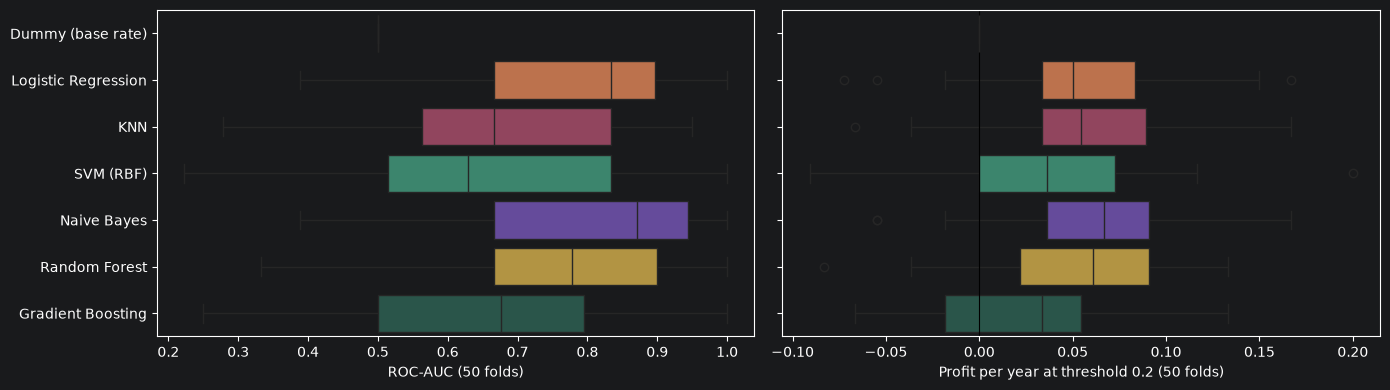

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
sns.boxplot(data=auc_runs, orient="h", ax=axes[0])
axes[0].set_xlabel("ROC-AUC (50 folds)")
sns.boxplot(data=profit_runs, orient="h", ax=axes[1])
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Profit per year at threshold 0.2 (50 folds)")
plt.tight_layout()
plt.show()

## Most significant variables for each model

Which features does each model actually rely on? We use **permutation importance**, which works the same way for every model type: fit the model on 4/5 of the training years, then shuffle one feature at a time in the held-out 1/5 and measure how much the ROC-AUC drops. A big drop means the model depends on that feature. This is repeated over the 5 folds × 10 repeats (`cv_rep`) and averaged, so every number comes from years the model did not train on.

All models use the default preprocessor (`small` feature set: `year`, `air_feb`, `snow_days`, `soil_moisture`), so we compare how differently they use the **same four** features. For logistic regression we also show its coefficients, which tell the **direction** of each effect.

In [31]:
from sklearn.inspection import permutation_importance

importance = {}
for name, pipe in pipelines.items():
    if name.startswith("Dummy"):
        continue
    drops = []
    for train_idx, val_idx in cv_rep.split(X_train, y_train):
        fitted = clone(pipe).fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        r = permutation_importance(fitted, X_train.iloc[val_idx], y_train.iloc[val_idx], scoring="roc_auc",
                                   n_repeats=5, random_state=RANDOM_STATE)
        drops.append(r.importances_mean)
    importance[name] = pd.Series(np.mean(drops, axis=0), index=X_train.columns)

importance = pd.DataFrame(importance)
importance = importance.loc[(importance.abs() > 1e-9).any(axis=1)]     # only the features the models actually see
importance.round(3)

,Logistic Regression,KNN,SVM (RBF),Naive Bayes,Random Forest,Gradient Boosting
year,-0.000,-0.029,0.038,0.011,0.014,-0.020
snow_days,0.077,0.068,0.119,0.064,0.090,0.071
soil_moisture,0.007,0.031,0.098,0.039,0.025,0.004
air_feb,0.061,0.034,-0.005,0.095,0.056,0.054


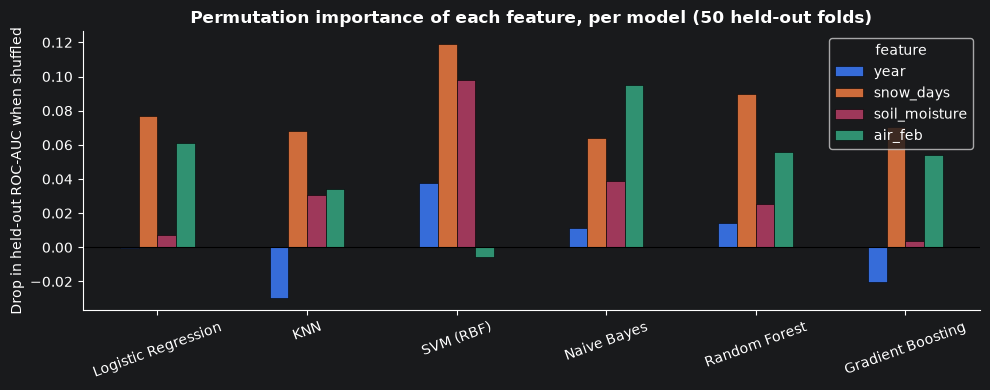

,logistic regression coefficient
year,0.145
air_feb,0.350
snow_days,-0.342
soil_moisture,0.235


In [32]:
fig, ax = plt.subplots(figsize=(10, 4))
importance.T.plot.bar(ax=ax, edgecolor="black", linewidth=0.4)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Drop in held-out ROC-AUC when shuffled")
ax.set_title("Permutation importance of each feature, per model (50 held-out folds)", fontweight="bold")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="feature")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# Direction of each effect: logistic regression coefficients (features are standardized, so they are comparable)
lr_fit = clone(pipelines["Logistic Regression"]).fit(X_train, y_train)
coefs = pd.Series(lr_fit.named_steps["model"].coef_[0],
                  index=lr_fit.named_steps["prep"].transform(X_train.head(1)).columns)
coefs.round(3).to_frame("logistic regression coefficient")

**How to read this.** Each bar is how much a model's ranking of *unseen* years gets worse when that feature is scrambled. A bar near 0 means the model can do without the feature; a negative bar means the feature was slightly *hurting* that model on new years.

**What we found:**

* **Snow-cover days (`snow_days`) and February air temperature (`air_feb`) are the two features that matter.** `snow_days` is the most important feature for logistic regression, the SVM, the random forest and gradient boosting (AUC drop 0.07–0.12); `air_feb` is the most important for naive Bayes (0.10). Counting trace snow as snow (Get the Data) is what made `snow_days` this useful.
* **The logistic-regression coefficients give the direction:** warmer February (+0.35) and wetter soil (+0.24) raise the chance of an early spring, more snow-cover days (−0.34) lower it, and `year` has a small positive effect (+0.15, the warming trend).
* **`year` barely matters inside the training years** (importance near 0 or slightly negative for every model), even though the trend is strong after 2010.
* **The SVM leans on `soil_moisture` much more than the others** and gets almost nothing from `air_feb`, so it uses the information differently from the rest.

## Types of errors

Which years does each model get wrong, and why? We use the out-of-fold probabilities from the model comparison above (`all_scores`: each year is predicted by a model that never saw it) and the business threshold of 0.2:

* **Missed early spring** (false negative): P(early) ≤ 0.2 but spring was early. Costs the extra harvest (0.8 R).
* **Wasted seeds** (false positive): P(early) > 0.2 but spring was not early. Costs 0.2 R.

In [33]:
models = [n for n in all_scores if not n.startswith("Dummy")]
decisions = pd.DataFrame({n: all_scores[n] > SEED_COST for n in models}, index=train_set["year"])
actual = pd.Series(y_train.values, index=train_set["year"])

error_types = pd.DataFrame({
    "missed early springs (FN)": [(~decisions[n] & actual).sum() for n in models],
    "wasted purchases (FP)":     [(decisions[n] & ~actual).sum() for n in models],
    "years bought":              [decisions[n].sum() for n in models],
}, index=models)
error_types["cost (R)"] = 0.8 * error_types["missed early springs (FN)"] + 0.2 * error_types["wasted purchases (FP)"]
error_types.sort_values("cost (R)")

,missed early springs (FN),wasted purchases (FP),years bought,cost (R)
KNN,3,12,20,4.8
Naive Bayes,3,13,21,5.0
Random Forest,4,11,18,5.4
SVM (RBF),5,9,15,5.8
Logistic Regression,3,18,26,6.0
Gradient Boosting,8,9,12,8.2


The models make the **two kinds of mistakes in different proportions**. Logistic regression buys most often (26 of 57 years) and misses only 3 early springs, but wastes seeds 18 times. KNN and naive Bayes buy in 20–21 years and also miss only 3. The SVM and gradient boosting are the most cautious (12–15 buys) and miss 5–8 early springs. Because a missed early spring costs **4 times** as much as a wasted purchase, gradient boosting, which misses the most, is by far the most expensive; KNN and naive Bayes have the lowest total cost.

In [34]:
# The early springs that the models miss: which years, and what their February looked like
missed = (~decisions).loc[actual]                      # True = this model did NOT buy in this early year
weather = train_set.set_index("year")[["air_feb", "snow_days", "cold_days", "soil_moisture"]].astype(float)
early_years = weather.loc[actual].round({"air_feb": 1, "soil_moisture": 3}).assign(**{"models that missed it": missed.sum(axis=1).astype(int)})
early_years.join(missed.replace({True: "missed", False: "bought"})).sort_values("models that missed it", ascending=False)

,air_feb,snow_days,cold_days,soil_moisture,models that missed it,Logistic Regression,KNN,SVM (RBF),Naive Bayes,Random Forest,Gradient Boosting
year,,,,,,,,,,,
1965,28.7,17.0,16.0,0.464,6,missed,missed,missed,missed,missed,missed
1982,29.2,27.0,14.0,0.485,6,missed,missed,missed,missed,missed,missed
2009,29.3,21.0,15.0,0.475,6,missed,missed,missed,missed,missed,missed
1953,33.4,6.0,8.0,0.480,2,bought,bought,missed,bought,bought,missed
1991,33.9,12.0,8.0,0.477,2,bought,bought,bought,bought,missed,missed
2000,36.4,22.0,8.0,0.475,2,bought,bought,missed,bought,bought,missed
1951,32.2,9.0,8.0,0.483,1,bought,bought,bought,bought,bought,missed
2001,35.9,12.0,5.0,0.474,1,bought,bought,bought,bought,bought,missed
1949,36.8,7.0,11.0,0.486,0,bought,bought,bought,bought,bought,bought


In [35]:
# Typical February in early-spring years, split by whether most models caught them or missed them
caught = early_years["models that missed it"] <= len(models) / 2
compare = pd.DataFrame({
    "early springs most models caught": weather.loc[early_years.index[caught]].mean(),
    "early springs most models missed": weather.loc[early_years.index[~caught]].mean(),
    "all late / normal years":          weather.loc[~actual].mean(),
}).round(3)
compare

,early springs most models caught,early springs most models missed,all late / normal years
air_feb,35.120,29.048,28.911
snow_days,10.375,21.667,20.783
cold_days,7.250,15.000,13.089
soil_moisture,0.480,0.474,0.472


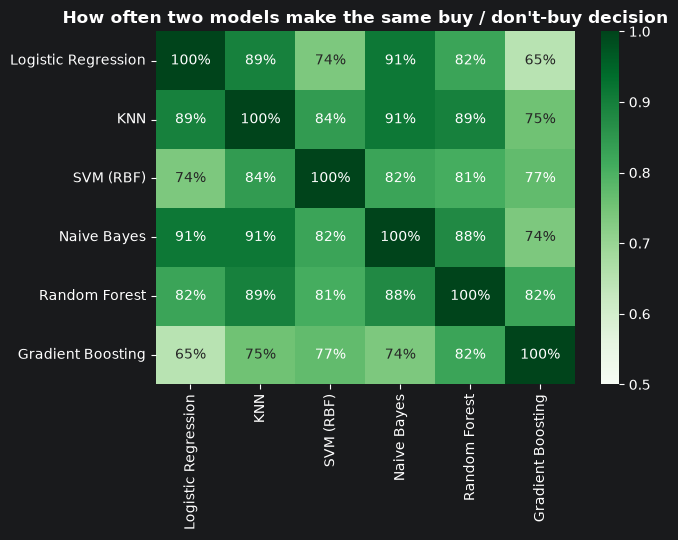

In [36]:
# Do the models make the SAME mistakes? Agreement between their buy / don't-buy decisions
agreement = pd.DataFrame({a: {b: (decisions[a] == decisions[b]).mean() for b in models} for a in models})
plt.figure(figsize=(7, 5.5))
sns.heatmap(agreement, annot=True, fmt=".0%", cmap="Greens", vmin=0.5, vmax=1)
plt.title("How often two models make the same buy / don't-buy decision", fontweight="bold")
plt.tight_layout()
plt.show()

**What the errors tell us:**

* **Three early springs fool every model: 1965, 1982 and 2009.** Their Februaries look exactly like a normal winter. Early springs that most models missed had an average February of about **29.0 °F with 22 snow-cover days**, while the average late/normal year had **28.9 °F with 21 snow-cover days**. The early springs the models catch are clearly warmer and less snowy (about 35 °F, 10 snow-cover days). From February data alone those three years cannot be told apart from late springs, so no model built on these features could catch them.
* **What a human would have used to avoid these errors:** information from **after** February, such as March–April weather or NOAA's late-February outlook for March–April. Spring is decided in late March and April, and our data stops at the end of February (the order deadline). It is the same limitation that shows up on the test years in the final evaluation.
* **Do the shortlisted models make different mistakes?** Mostly not. Logistic regression, naive Bayes and KNN make the **same buy / don't-buy decision in 89–91% of the years** (heatmap), and the random forest agrees with them in 82–89%. **Gradient boosting** (65–75% agreement with those four) and the **SVM** (74–84%) are the ones that err differently. The checklist suggests preferring models that make *different* errors, which is a good reason to **also tune gradient boosting** in the next section (besides it being a required ensemble), and it explains why a voting ensemble of three similar models can't gain much.

**Another round of feature selection and engineering (checklist items 5–6).** The quick round of feature selection and engineering was done in the Preparation notebook (random-forest importances, feature sets, `log1p`, rule flag, polynomial features). Rather than repeat it by hand here, the fine-tuning below treats those preparation choices as **hyperparameters** (`prep__features__feature_set`, `prep__poly__degree`, ...), so the search runs that iteration automatically for every model.

## Which models to continue with

All seven models were scored with the same repeated cross-validation (5 folds x 10 repeats = 50 fits each) at the break-even threshold of 0.2. The table repeats the numbers from the boxplot cell above; the naive strategies earn 0 (never buy), -0.007 (always buy) and -0.014 (follow Phil) per year on the same years.

| Model | AUC (mean) | Profit per year (mean ± sd over the 50 folds) |
|---|---|---|
| Naive Bayes | 0.802 | 0.063 ± 0.048 |
| KNN | 0.686 | 0.056 ± 0.047 |
| Random Forest | 0.755 | 0.056 ± 0.047 |
| Logistic Regression | 0.789 | 0.053 ± 0.047 |
| SVM (RBF) | 0.657 | 0.034 ± 0.053 |
| Gradient Boosting | 0.652 | 0.026 ± 0.054 |
| Dummy (base rate) | 0.500 | 0.000 |

The top four models differ by only 0.01 in profit per year, while the fold-to-fold spread is about 0.05. The data therefore cannot rank them, so we shortlist **four** (the checklist allows 3–5), each in the top group and each a different kind of model:

* **Naive Bayes**: the best profit and the best AUC, with almost no complexity. It has few model hyperparameters, so most of its tuning comes from the preprocessing options.
* **Logistic Regression**: second-best AUC, simple, with well-behaved probabilities and many knobs to tune.
* **KNN**: in the top group on profit, and a different kind of model (local, distance-based), which helps in an ensemble. Its probabilities are coarse (multiples of 1/k), so we tune `n_neighbors` and the weighting.
* **Random Forest**: the same profit as KNN with a much better AUC (0.76), and a tree ensemble, which the project requires us to tune.

**Different types of errors (checklist).** The *Types of errors* section showed that these four make the same buy / don't-buy decision in most years (82–91%). Gradient boosting disagrees with them the most, which is a reason to tune it too, even though untuned it is the weakest real model.

**Not shortlisted, but still tuned:** gradient boosting earns little untuned (0.03 per year, about half a standard deviation above the dummy). It is tuned anyway because the project requires a tuned ensemble with many hyperparameters and because it makes different errors. The SVM (0.03 per year, AUC 0.66) is dropped. A soft-voting ensemble of naive Bayes, logistic regression and KNN is built afterwards as an extra.

**Caveats to keep in mind**

* The `small` feature set was chosen in Preparation using all the training years, so these scores are somewhat optimistic.
* The test years have far more early springs (about 47%) than the training years (19%). A model that rarely buys here may be too cautious later, so the final evaluation compares against the test set's own never-buy / always-buy baselines.

## Fine-tuning

For each shortlisted model, and for the two tree ensembles, we tune the model's own hyperparameters **together with the preprocessing**, because the best feature set, scaler or imputer may depend on the model.

**Preprocessing hyperparameters (9, shared by every model):** which feature set (`small`, `selected`, `all`), whether to keep `year`, Phil's call and the climate indices, `log1p` of skewed features, missing-value flags, the imputer strategy (median or mean), the scaler (standard or robust) and the polynomial degree (1 or 2).

**Model hyperparameters:**

| Model | Model hyperparameters | Preprocessing | Total |
|---|---|---|---|
| Logistic Regression | 4 (`C`, `class_weight`, `solver`, `fit_intercept`) | 9 | 13 |
| Naive Bayes | 2 (`var_smoothing`, `priors`) | 9 | 11 |
| KNN | 3 (`n_neighbors`, `weights`, `p`) | 9 | 12 |
| Random Forest | 11 (trees, depth, leaf sizes, split sizes, `max_features`, `class_weight`, `max_samples`, `criterion`, `ccp_alpha`, `min_impurity_decrease`, `max_leaf_nodes`) | 9 | 20 |
| Gradient Boosting | 11 (trees, learning rate, depth, leaf sizes, split sizes, `subsample`, `max_features`, `loss`, `ccp_alpha`, `min_impurity_decrease`, `max_leaf_nodes`) | 9 | 20 |

The tree ensembles cover a wide range, from very shallow and heavily regularized trees (depth 1, large leaves, few features) to deeper ones, so the search can find out how much regularization 57 years need. `ccp_alpha` and the learning rate are sampled on a log scale; everything else from a list of values.

In [37]:
from scipy.stats import loguniform
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, StandardScaler

N_ITER = 40        # random combinations tried per model

# Preprocessing hyperparameters (names from the Preparation notebook), shared by every model
prep_space = {
    "prep__features__feature_set":       ["small", "selected", "all"],
    "prep__features__use_year":          [True, False],
    "prep__features__use_phil":          [True, False],
    "prep__features__use_indices":       [True, False],
    "prep__features__log_skewed":        [True, False],
    "prep__features__add_missing_flags": [True, False],
    "prep__impute__step__strategy":      ["median", "mean"],
    "prep__scale__step":                 [StandardScaler(), RobustScaler()],
    "prep__poly__degree":                [1, 2],
}

# Each model with its own hyperparameters
search_space = {
    "Logistic Regression": (LogisticRegression(max_iter=5000),
        {"model__C": loguniform(1e-3, 1e1), "model__class_weight": [None, "balanced"],
         "model__solver": ["lbfgs", "liblinear"], "model__fit_intercept": [True, False]}),
    "Naive Bayes": (GaussianNB(),
        {"model__var_smoothing": loguniform(1e-9, 1e-1),
         "model__priors": [None, [0.9, 0.1], [0.8, 0.2], [0.7, 0.3]]}),
    "KNN": (KNeighborsClassifier(),
        {"model__n_neighbors": [3, 5, 7, 9, 11, 15], "model__weights": ["uniform", "distance"], "model__p": [1, 2]}),
    # The two tree ensembles: 11 model hyperparameters each, over a wide range
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE),
        {"model__n_estimators": [50, 100, 200, 300, 400],
         "model__max_depth": [1, 2, 3, 4, 6, 8, None],
         "model__min_samples_leaf": [1, 2, 3, 5, 8],
         "model__min_samples_split": [2, 4, 8, 12],
         "model__max_features": ["sqrt", "log2", 0.3, 0.5, 0.8, 1.0],
         "model__class_weight": [None, "balanced", "balanced_subsample"],
         "model__max_samples": [None, 0.5, 0.7, 0.9],
         "model__criterion": ["gini", "entropy", "log_loss"],
         "model__ccp_alpha": loguniform(1e-4, 3e-2),
         "model__min_impurity_decrease": [0.0, 0.001, 0.005, 0.01],
         "model__max_leaf_nodes": [None, 4, 8, 16]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=RANDOM_STATE),
        {"model__n_estimators": [50, 100, 200, 300, 400],
         "model__learning_rate": loguniform(0.01, 0.3),
         "model__max_depth": [1, 2, 3, 4],
         "model__min_samples_leaf": [1, 2, 3, 5, 8],
         "model__min_samples_split": [2, 4, 8, 12],
         "model__subsample": [0.5, 0.7, 0.85, 1.0],
         "model__max_features": ["sqrt", "log2", 0.5, None],
         "model__loss": ["log_loss", "exponential"],
         "model__ccp_alpha": loguniform(1e-4, 3e-2),
         "model__min_impurity_decrease": [0.0, 0.001, 0.005, 0.01],
         "model__max_leaf_nodes": [None, 4, 8, 16]}),
}
for name, (_, space) in search_space.items():
    print(f"{name}: {len(prep_space)} preprocessing + {len(space)} model hyperparameters")

Logistic Regression: 9 preprocessing + 4 model hyperparameters
Naive Bayes: 9 preprocessing + 2 model hyperparameters
KNN: 9 preprocessing + 3 model hyperparameters
Random Forest: 9 preprocessing + 11 model hyperparameters
Gradient Boosting: 9 preprocessing + 11 model hyperparameters


### Randomized search, scored on profit

For every model we try `N_ITER` random combinations of preprocessing and model hyperparameters and keep the one with the best **profit per year at the 0.2 threshold**, measured with repeated cross-validation (4 repeats of 5 folds). ROC-AUC is recorded as a second metric but does not choose the winner.

**Why profit and not AUC?** For logistic regression that picked `C = 0.0013`, which shrinks every predicted probability toward the base rate (about 0.19, just under the 0.2 threshold). The *ranking* of the years stayed fine (AUC 0.79 in the search), but at the 0.2 cutoff the model bought almost at random, and in that earlier run its repeated-CV profit dropped from about 0.05 (untuned) to about **-0.01** (tuned). We buy whenever P(early) > 0.2, so the probabilities themselves have to be sensible, not just their order. Scoring on profit tunes what the client actually earns.

**Caveats:** profit at a fixed threshold is noisier than AUC (only 11 early springs), and the best of 40 random settings is selected on the same folds it is scored on, so the "best CV profit" below is optimistic. The next cell re-scores the winners on fresh folds.

In [38]:
# Randomized search over preprocessing + model hyperparameters, scored on profit per year at 0.2
# (ROC-AUC is recorded too). Profit is noisy with ~11 early springs, so use 4 repeats of 5-fold CV.
cv_search = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=RANDOM_STATE)
search_scoring = {"profit": profit_score, "auc": "roc_auc"}

tuned, rows = {}, []
for name, (model, space) in search_space.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    search = RandomizedSearchCV(pipe, {**prep_space, **space}, n_iter=N_ITER, cv=cv_search,
                                scoring=search_scoring, refit="profit",
                                random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    i = search.best_index_
    rows.append({"model": name,
                 "best CV profit (optimistic)": search.cv_results_["mean_test_profit"][i],
                 "CV AUC of that setting": search.cv_results_["mean_test_auc"][i],
                 **search.best_params_})
tuning_results = pd.DataFrame(rows).set_index("model")
display(tuning_results.iloc[:, :2].round(3))
tuning_results.iloc[:, 2:].T       # the winning settings for each model

,best CV profit (optimistic),CV AUC of that setting
model,,
Logistic Regression,0.067,0.761
Naive Bayes,0.077,0.739
KNN,0.076,0.725
Random Forest,0.073,0.744
Gradient Boosting,0.064,0.778


model,Logistic Regression,Naive Bayes,KNN,Random Forest,Gradient Boosting
model__C,0.234238,NaN,NaN,NaN,NaN
model__class_weight,NaN,NaN,NaN,NaN,NaN
model__fit_intercept,True,NaN,NaN,NaN,NaN
model__solver,lbfgs,NaN,NaN,NaN,NaN
prep__features__add_missing_flags,True,False,True,True,False
prep__features__feature_set,small,all,selected,selected,small
prep__features__log_skewed,True,True,False,True,False
prep__features__use_indices,True,False,False,False,True
prep__features__use_phil,False,False,False,True,True
prep__features__use_year,False,False,False,False,True


**A note on the winning settings.** The searches did not all agree with Preparation. The tuned **naive Bayes** (our eventual final model) uses **all 21 features with degree-2 polynomial features**, and the tuned logistic regression also picked degree 2, while Preparation concluded that fewer features and no polynomial features work best. That is not a contradiction: Preparation compared options using AUC, while the search scores **profit at the 0.2 threshold** and picks the best of 40 random settings on the same folds, so a small and possibly lucky gain is enough to win. The re-scoring on fresh folds below checks whether it holds up, and the calibration check further down shows the cost of these settings: with hundreds of correlated inputs, naive Bayes becomes extremely overconfident.

### Re-scoring the tuned models on fresh folds

The search picks the best of many random settings, so its own score is too good to be true. To compare fairly we re-score every tuned model with a **different random split** (10 repeats of 5-fold, 50 fits each, a seed the search never saw) and put the result next to the untuned profit from the model comparison above.

How to read the table: a tuned model is only an improvement if its profit mean is higher than the untuned one by more than the spread (the `profit sd` column, about 0.05). The data are too few to detect smaller gains. The `candidate_cv` table is also what the final model is chosen from, so the choice never depends on the test set.

In [39]:
# Re-score every tuned model with fresh folds (a different random split than the search used)
cv_check = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE + 1)

def rescore(est):
    r = cross_validate(est, X_train, y_train, cv=cv_check, n_jobs=-1,
                       scoring={"auc": "roc_auc", "profit": profit_score})
    return pd.Series({"AUC mean": r["test_auc"].mean(), "AUC sd": r["test_auc"].std(),
                      "profit mean": r["test_profit"].mean(), "profit sd": r["test_profit"].std()})

candidate_cv = pd.DataFrame({name: rescore(est) for name, est in tuned.items()}).T
candidate_cv.join(summary["profit mean"].rename("untuned profit mean")).round(3)

,AUC mean,AUC sd,profit mean,profit sd,untuned profit mean
Logistic Regression,0.737,0.191,0.063,0.054,0.053
Naive Bayes,0.743,0.207,0.070,0.055,0.063
KNN,0.701,0.192,0.068,0.053,0.056
Random Forest,0.725,0.223,0.064,0.049,0.056
Gradient Boosting,0.735,0.195,0.056,0.057,0.026


### The buy threshold

A model outputs P(early spring), and we buy when it exceeds a threshold. The plot shows the profit per year at every threshold for each tuned model, using out-of-fold probabilities (a single 5-fold run).

**We keep the break-even threshold of 0.2.** A purchase gains 0.8 when spring is early and loses 0.2 when it is not, so buying pays off on average whenever P(early) > 0.2. If a model's probabilities are well calibrated, 0.2 is the best cutoff and needs no tuning.

The "best" threshold printed for each model is the peak of a noisy curve (101 thresholds, 11 early springs), picked on the same years it is scored on, so it is **optimistic and unstable**. A big gap between the profit at 0.2 and at the in-sample best threshold does not mean we found a better cutoff. It means the model's probabilities are not calibrated to the 0.2 break-even, which is exactly what the profit-based search above tries to avoid. A threshold tuned this way would be one more hyperparameter chosen from 57 noisy points, so we do not use it.

**What the client told us about the threshold.** The farmers are a consortium and each one decides alone; some are more risk-averse. Each purchase also causes extra wear and tear on equipment and land that is not in the 0.2 R seed cost, so the real break-even is a bit **above** 0.2. We therefore keep 0.2 as the standard threshold for model selection, and report in the Presentation what a more cautious farmer (threshold 0.3 or 0.4) would have earned.

Logistic Regression  profit at 0.2: +0.074 | at in-sample best threshold 0.23: +0.077  (optimistic)
Naive Bayes          profit at 0.2: +0.084 | at in-sample best threshold 0.14: +0.084  (optimistic)
KNN                  profit at 0.2: +0.074 | at in-sample best threshold 0.15: +0.074  (optimistic)
Random Forest        profit at 0.2: +0.077 | at in-sample best threshold 0.20: +0.077  (optimistic)
Gradient Boosting    profit at 0.2: +0.063 | at in-sample best threshold 0.14: +0.067  (optimistic)


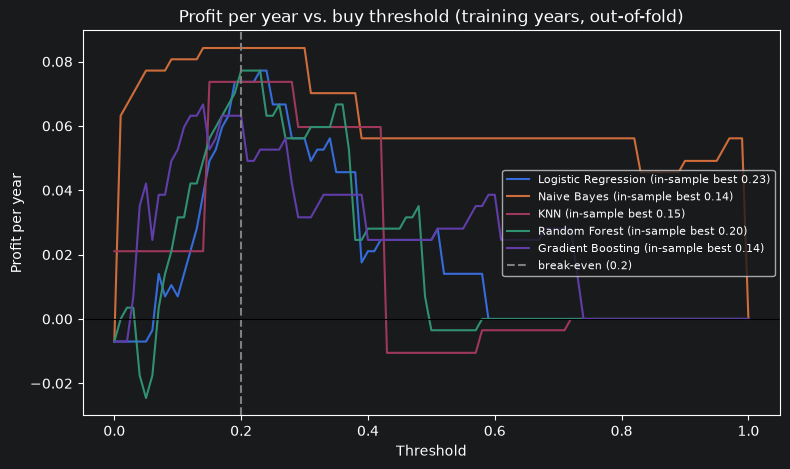

In [40]:
# Profit per year at every threshold, for each tuned model (out-of-fold probabilities, one 5-fold run)
thresholds = np.linspace(0, 1, 101)
plt.figure(figsize=(9, 5))
best_in_sample = {}
for name, est in tuned.items():
    scores = cross_val_predict(est, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    profits = [profit_per_year(y_train, scores > t) for t in thresholds]
    best_in_sample[name] = thresholds[int(np.argmax(profits))]
    plt.plot(thresholds, profits, label=f"{name} (in-sample best {best_in_sample[name]:.2f})")
    print(f"{name:20s} profit at 0.2: {profit_per_year(y_train, scores > SEED_COST):+.3f} | "
          f"at in-sample best threshold {best_in_sample[name]:.2f}: {max(profits):+.3f}  (optimistic)")
plt.axvline(SEED_COST, color="gray", linestyle="--", label="break-even (0.2)")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Threshold")
plt.ylabel("Profit per year")
plt.title("Profit per year vs. buy threshold (training years, out-of-fold)")
plt.legend(fontsize=8)
plt.show()

### Can the farmers trust the probabilities?

Some farmers asked for the **chance** of an early spring, not just a yes/no (client email). A probability is only useful if it is honest: among years where the model says about 30%, about 30% should be early springs. We check this on the **training years only** (out-of-fold probabilities), with two measures:

* **Brier score**: the average squared gap between the predicted probability and what happened (0 = perfect; always predicting the training base rate of 19% scores about 0.16).
* **Share of extreme predictions**: how often a model says below 5% or above 95%. With only 11 early springs in 57 years, such confident predictions are rarely justified.

In [41]:
from sklearn.metrics import brier_score_loss

calib = {}
for name, est in tuned.items():
    p = cross_val_predict(est, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    calib[name] = {"Brier score": brier_score_loss(y_train, p),
                   "% predictions < 5% or > 95%": np.mean((p < 0.05) | (p > 0.95)) * 100,
                   "mean predicted P(early)": p.mean()}
calib["Base rate only (always 19%)"] = {"Brier score": brier_score_loss(y_train, np.full(len(y_train), y_train.mean())),
                                         "% predictions < 5% or > 95%": 0.0, "mean predicted P(early)": y_train.mean()}
pd.DataFrame(calib).T.round(3)

,Brier score,% predictions < 5% or > 95%,mean predicted P(early)
Logistic Regression,0.131,0.000,0.193
Naive Bayes,0.197,87.719,0.255
KNN,0.149,40.351,0.175
Random Forest,0.139,17.544,0.183
Gradient Boosting,0.142,33.333,0.177
Base rate only (always 19%),0.156,0.000,0.193


**What we found** (training years, out-of-fold):

* **Logistic regression gives the most trustworthy probabilities**: the best Brier score (0.131, below the base-rate line of 0.156) and never an extreme prediction.
* **Naive Bayes, our final model, gives the least trustworthy ones.** Its Brier score (0.197) is **clearly worse than just quoting the historical rate of 19%**, and **88% of its predictions** are below 5% or above 95%. Naive Bayes treats every feature as independent. The tuned version uses all 21 features plus their squares and products, so evidence that is really one signal counted many times (February air temperature, cold days and snow all describe the same cold winter) piles up into near-certain answers.
* KNN, the random forest and gradient boosting are in between (Brier 0.14–0.15, 18–40% extreme predictions).

We only **report** this and do not change the selection rule, which was fixed before the test set and chose by profit. But it matters for the client: if farmers are shown a probability, it should come from a better-calibrated model (logistic regression), or naive Bayes should be calibrated first. This is listed as a limitation in the Presentation.

### An extra ensemble: soft voting

A soft-voting classifier averages the predicted probabilities of the three tuned shortlisted models (logistic regression, naive Bayes and KNN). Only its weights are tuned (4 settings), so this is a cheap extra. The tuned Random Forest and Gradient Boosting above are the ensembles that carry the many-hyperparameter tuning. The voting ensemble is then scored on the same fresh folds and added to the candidate table.

In [42]:
# A soft-voting ensemble of the three tuned shortlisted models, with its weights tuned on profit
VOTING_NAME = "Voting (LR + NB + KNN)"
members = [(n.replace(" ", "_"), tuned[n]) for n in ["Logistic Regression", "Naive Bayes", "KNN"]]
weight_search = GridSearchCV(VotingClassifier(members, voting="soft"),
                             {"weights": [[1, 1, 1], [2, 1, 1], [1, 2, 1], [1, 1, 2]]},
                             cv=cv_search, scoring=profit_score, n_jobs=-1)
weight_search.fit(X_train, y_train)
best_ensemble = weight_search.best_estimator_
print("best weights:", weight_search.best_params_["weights"],
      "| CV profit (optimistic):", round(weight_search.best_score_, 3))

candidate_cv.loc[VOTING_NAME] = rescore(best_ensemble)
candidate_cv.round(3)

best weights: [1, 2, 1] | CV profit (optimistic): 0.077


,AUC mean,AUC sd,profit mean,profit sd
Logistic Regression,0.737,0.191,0.063,0.054
Naive Bayes,0.743,0.207,0.070,0.055
KNN,0.701,0.192,0.068,0.053
Random Forest,0.725,0.223,0.064,0.049
Gradient Boosting,0.735,0.195,0.056,0.057
Voting (LR + NB + KNN),0.736,0.193,0.067,0.057


## Choosing the final model

**Selection rule (fixed before looking at the test set, using training years only):** the final model is the candidate with the **highest mean profit per year in the repeated cross-validation on fresh folds**, at the break-even threshold of 0.2. The profit differences among the top candidates are usually smaller than the fold-to-fold spread, so the choice among them is not strongly supported by the data, but a fixed rule keeps the test set out of the decision.

In [43]:
# The final model and threshold come from the TRAINING cross-validation only
candidates = {**tuned, VOTING_NAME: best_ensemble}
FINAL_NAME = candidate_cv["profit mean"].idxmax()
FINAL_MODEL = candidates[FINAL_NAME]
THRESHOLD = SEED_COST

display(candidate_cv.sort_values("profit mean", ascending=False).round(3))
print(f"Final model: {FINAL_NAME} | threshold: {THRESHOLD} (break-even)")

,AUC mean,AUC sd,profit mean,profit sd
Naive Bayes,0.743,0.207,0.070,0.055
KNN,0.701,0.192,0.068,0.053
Voting (LR + NB + KNN),0.736,0.193,0.067,0.057
Random Forest,0.725,0.223,0.064,0.049
Logistic Regression,0.737,0.191,0.063,0.054
Gradient Boosting,0.735,0.195,0.056,0.057


Final model: Naive Bayes | threshold: 0.2 (break-even)


## Final evaluation on the test set

The test set is loaded here for the first time. The final model is fit on all the training years and then makes one prediction per test year: buy if P(early spring) > 0.2. We compare its profit per year with the naive strategies **computed on the test years' own labels**, because the test years have a very different base rate (about 47% early springs, against 19% in training), and that changes what "always buy" earns.

Nothing is changed after this cell. If the model does not beat the baselines, that is reported as it is. The cell ends with a short verdict computed from the numbers.

Final model: Naive Bayes
Test years: 15, early springs: 7 (47%)

Model          0.107
Never buy      0.000
Always buy     0.267
Follow Phil    0.200

ROC-AUC: 0.375 | buys in 7 of 15 years


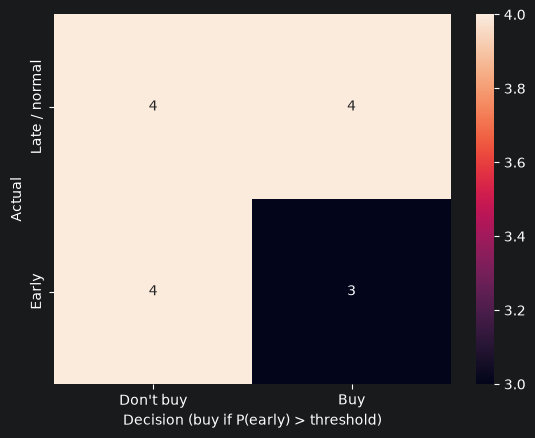

VERDICT
  Training CV : Naive Bayes earned +0.070 per year; best naive strategy (Never buy): +0.000
  Test 2012-2026: model earned +0.107 per year; best naive strategy (Always buy): +0.267; test AUC 0.37
  -> The model does NOT beat the best naive strategy (Always buy) on the test years.
     Its ranking of the years is worse than random (AUC < 0.5): the training patterns did not carry over.
  (Only 15 years with 7 early springs: treat the test result as indicative, not precise.)


In [44]:
# Evaluate FINAL_MODEL and THRESHOLD on the test set ONCE
test_set = pd.read_parquet("test_set.parquet")
X_test, y_test = test_set.drop(columns=TARGET), test_set[TARGET].astype(bool)

FINAL_MODEL.fit(X_train, y_train)
p_test = FINAL_MODEL.predict_proba(X_test)[:, 1]
buy = p_test > THRESHOLD

phil_test = X_test["phil_early"].fillna(False).astype(bool)
model_profit = profit_per_year(y_test, buy)
naive_test = {"Never buy": 0.0,
              "Always buy": profit_per_year(y_test, np.ones(len(y_test))),
              "Follow Phil": profit_per_year(y_test, phil_test)}
auc_test = roc_auc_score(y_test, p_test)

print(f"Final model: {FINAL_NAME}")
print(f"Test years: {len(y_test)}, early springs: {y_test.sum()} ({y_test.mean():.0%})\n")
print(pd.Series({"Model": model_profit, **naive_test}).round(3).to_string())
print(f"\nROC-AUC: {auc_test:.3f} | buys in {int(buy.sum())} of {len(buy)} years")

sns.heatmap(confusion_matrix(y_test, buy, labels=[False, True]), annot=True, fmt="d",
            xticklabels=["Don't buy", "Buy"], yticklabels=["Late / normal", "Early"])
plt.xlabel("Decision (buy if P(early) > threshold)")
plt.ylabel("Actual")
plt.show()

# ── Verdict, computed from the numbers above ──
cv_naive = {"Never buy": 0.0, "Always buy": profit_per_year(y_train, np.ones(len(y_train))),
            "Follow Phil": profit_per_year(y_train, phil)}
best_cv_naive = max(cv_naive, key=cv_naive.get)
best_test_naive = max(naive_test, key=naive_test.get)
years = f"{test_set['year'].min()}-{test_set['year'].max()}"

print("VERDICT")
print(f"  Training CV : {FINAL_NAME} earned {candidate_cv.loc[FINAL_NAME, 'profit mean']:+.3f} per year; "
      f"best naive strategy ({best_cv_naive}): {cv_naive[best_cv_naive]:+.3f}")
print(f"  Test {years}: model earned {model_profit:+.3f} per year; "
      f"best naive strategy ({best_test_naive}): {naive_test[best_test_naive]:+.3f}; test AUC {auc_test:.2f}")
gap = round(model_profit, 3) - round(naive_test[best_test_naive], 3)
if gap > 0:
    print("  -> The model beats every naive strategy on the test years.")
elif gap == 0:
    print(f"  -> The model only matches the best naive strategy ({best_test_naive}) on the test years: it adds nothing over it.")
else:
    print(f"  -> The model does NOT beat the best naive strategy ({best_test_naive}) on the test years.")
if auc_test < 0.5:
    print("     Its ranking of the years is worse than random (AUC < 0.5): the training patterns did not carry over.")
print(f"  (Only {len(y_test)} years with {y_test.sum()} early springs: treat the test result as indicative, not precise.)")

### Why did the result come out this way?

The cell below compares each feature's correlation with early spring in the training years and in the test years. It is only an explanation of the result above. **It must not be used to change the features or the model**, because that would turn the test set into a second training set.

What the data show (from the table, and checked against the raw weather files): the February features that predicted early springs in the training years do not do so in the test years. February air temperature had a correlation of about **+0.40** with early spring in the training years and about **-0.13** in the test years. The coldest and snowiest February of the test period (2015, about 16 °F mean air temperature and 26 days of snow cover) was still an early spring, while warm, snow-free Februaries (2017 and 2023) were not. With about 47% early springs in the test years, always buying is then very hard to beat, and a model trained on the older pattern ranks the years badly.

In [45]:
# Post hoc explanation only: feature-label correlation in the training years vs the test years
corr_cmp = pd.DataFrame({"train r": X_train.astype(float).corrwith(y_train.astype(float)),
                         "test r":  X_test.astype(float).corrwith(y_test.astype(float))})
corr_cmp["change"] = corr_cmp["test r"] - corr_cmp["train r"]

print(f"Early spring rate: training years {y_train.mean():.0%} | test years {y_test.mean():.0%}\n")
corr_cmp.reindex(corr_cmp["train r"].abs().sort_values(ascending=False).index).head(10).round(2)

Early spring rate: training years 19% | test years 47%



,train r,test r,change
snow_days,-0.40,-0.20,0.19
air_feb,0.40,-0.13,-0.53
snow_days_late,-0.31,0.11,0.43
cold_days,-0.31,-0.02,0.29
soil_moisture,0.29,-0.10,-0.39
soil_feb,0.24,-0.40,-0.64
gdd,0.22,-0.29,-0.52
air_feb_late,0.21,-0.35,-0.56
soil_feb_late,0.21,-0.52,-0.73
ao_nov,-0.18,-0.02,0.16


## Saving the final model

`model.pkl` holds the final model **with its preprocessor inside** (every model here is a `Pipeline` that starts with the `prep` step, so imputing, scaling and feature engineering are included). It is the model that was evaluated above, fit on the training years only. The buy threshold is the break-even `SEED_COST = 0.2`, so a prediction is `model.predict_proba(X_new)[:, 1] > 0.2`.

To use it, `early_spring_prep.py` must be importable (the pickle refers to its classes). The cell reloads the file and checks that it gives the same probabilities on the test set.

In [46]:
with open("model.pkl", "wb") as f:
    pickle.dump(FINAL_MODEL, f)

# Reload it the way a user would, and check that it reproduces the test predictions
with open("model.pkl", "rb") as f:
    reloaded = pickle.load(f)
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], p_test)
print(f"model.pkl saved ({FINAL_NAME}) and reloaded: identical predictions on the test set.")

model.pkl saved (Naive Bayes) and reloaded: identical predictions on the test set.


## What we learned

* **Training and test years are different.** The early-spring rate is about 19% in the training years and about 47% in the test years, so the naive strategies change too. Always buying loses a little in training and earns clearly more on the test years, because a purchase only has to pay off 1 time in 5.
* **Model comparison.** On the training years, several models earned a small, consistent profit (about 0.05 per year) over the naive strategies, but the differences among the top models were smaller than the fold-to-fold spread, so we cannot say which is best.
* **Tuning.** Scoring the search on AUC made logistic regression worse at making money, because it shrank the probabilities toward the base rate. Tuning on profit fixes that. Tuned scores are still optimistic, so they were re-scored on fresh folds.
* **Threshold.** We kept the break-even threshold of 0.2 instead of tuning it, because an in-sample best threshold is a noisy, optimistic estimate.
* **Most important variables.** February snow-cover days and February air temperature carry almost all of the signal: more snow means a lower chance of an early spring, a warmer February a higher one.
* **Errors.** Three early springs (1965, 1982, 2009) fooled every model: their Februaries looked like a normal late winter. Catching them would need weather from after February, which the March 1 deadline rules out.
* **Probabilities.** The final model (naive Bayes) chose the most profitable setting, but its probabilities are extreme (88% below 5% or above 95%) and less trustworthy than the base rate. Logistic regression gives far better probabilities.
* **Test result.** The final model earned **+0.107 R per year** on 2012-2026, below **always buy (+0.267)** and **follow Phil (+0.200)**, with a test ROC-AUC of 0.37 (worse than random). It does **not** meet the client's bar of beating the simple strategies. The post-hoc section explains why: the relationship between February weather and early spring that the model learned from 1947-2010 did not hold in 2012-2026. With only 15 test years (7 early springs), the exact numbers are indicative, not precise.
* **Recommendation for the presentation.** Report the test result as it is: the training cross-validation was optimistic about how well the older pattern would carry over, and under the current climate (about half the springs early, far above the 1-in-5 break-even) buying every year is the better strategy for every farmer, cautious or not.